In [1]:
# Find hazeguard/ and import the shared config, so paths always work
import sys, pathlib
import pandas as pd

ROOT = pathlib.Path.cwd()
while not (ROOT / "pipeline").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "pipeline").exists():
    ROOT = pathlib.Path.cwd() / "hazeguard"   # opened from ibm-larp/
sys.path.insert(0, str(ROOT))

from pipeline.physical.config import RAW_DIR
print(RAW_DIR)

C:\Users\david\source\ibm-larp\hazeguard\data\raw


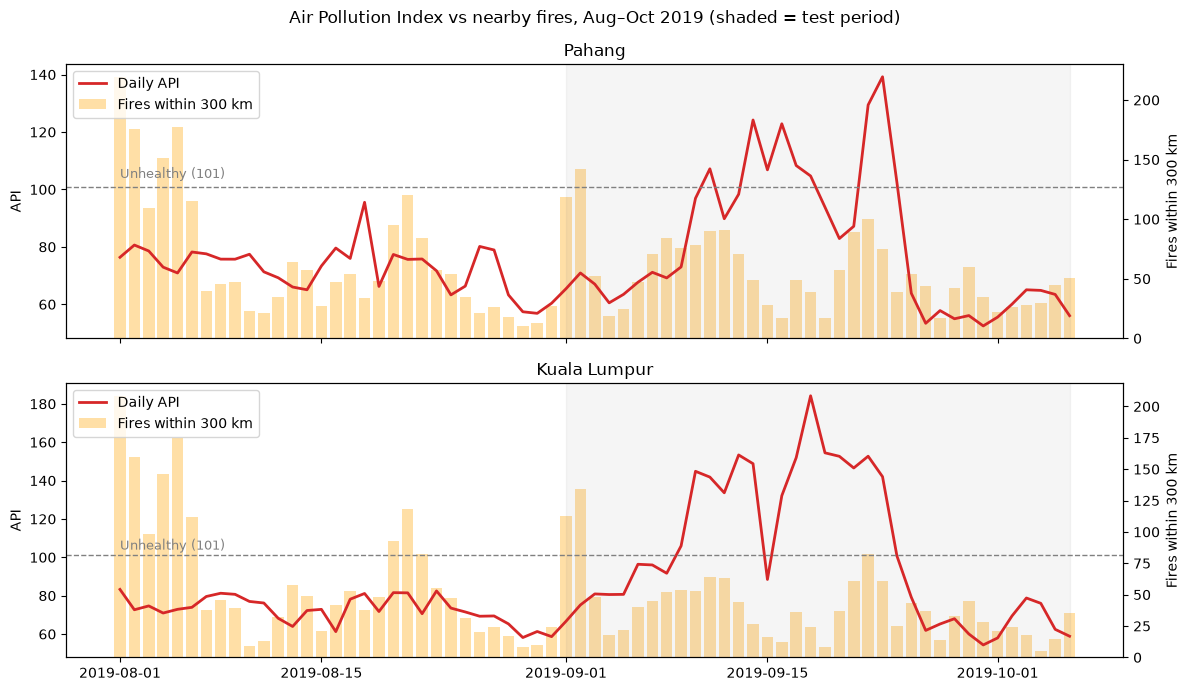

In [2]:
import matplotlib.pyplot as plt
from pipeline.physical.config import PROCESSED_DIR, UNHEALTHY_API, TEST_START, TEST_END, ROOT

# Daily API per state + your features, Aug to early Oct 2019
feat = pd.read_csv(PROCESSED_DIR / "features.csv", parse_dates=["date"])
api = pd.read_csv(PROCESSED_DIR / "api_states.csv", parse_dates=["time"])
api["date"] = api["time"].dt.floor("D")
api_daily = api.groupby(["state", "date"])["api"].mean().reset_index()

d = feat.merge(api_daily, on=["state", "date"], how="left")
d = d[(d.date >= "2019-08-01") & (d.date <= "2019-10-06")]

states = ["Pahang", "Kuala Lumpur"]          # strong local-fire state vs urban state
fig, axes = plt.subplots(len(states), 1, figsize=(12, 7), sharex=True)

for ax, s in zip(axes, states):
    x = d[d.state == s]
    ax2 = ax.twinx()                                           # second y-axis for fire counts
    ax2.bar(x.date, x.fires_300km, color="orange", alpha=0.35, label="Fires within 300 km")
    ax.plot(x.date, x.api, color="tab:red", lw=2, label="Daily API")
    ax.axhline(UNHEALTHY_API, ls="--", color="grey", lw=1)
    ax.text(x.date.iloc[0], UNHEALTHY_API + 3, "Unhealthy (101)", color="grey", fontsize=9)
    ax.axvspan(pd.Timestamp(TEST_START), pd.Timestamp(TEST_END), color="grey", alpha=0.08)

    ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)   # API line drawn over bars
    ax.set_title(s); ax.set_ylabel("API"); ax2.set_ylabel("Fires within 300 km")
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc="upper left")

fig.suptitle("Air Pollution Index vs nearby fires, Aug–Oct 2019 (shaded = test period)")
fig.tight_layout()

out = ROOT / "figures"; out.mkdir(exist_ok=True)
fig.savefig(out / "api_vs_fires_2019.png", dpi=150)